# Agrupamiento de canciones mediante K-Means

**Proyecto introductorio a Machine Learning no supervisado**

En esta clase vamos a descubrir cómo una computadora puede encontrar grupos de canciones similares **sin que le digamos de antemano** a qué categoría pertenece cada una.

Usaremos:
1. Un ejemplo pequeño (5 canciones) para entender la idea.
2. Un dataset público real de Spotify (560 canciones) para aplicar K-Means a un problema más cercano a la realidad.

**Dataset público:** [Spotify Tracks Dataset](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset) (Maharshi Pandya), con características de audio obtenidas mediante la API de Spotify.


## 1. Introducción al problema

Imaginemos una plataforma de música.

Tiene información sobre muchas canciones, pero **no tiene una clasificación previa** que indique a qué tipo de canción pertenece cada una.

Cada canción posee características numéricas, por ejemplo:

- **Energía**: qué tan intensa o activa suena.
- **Bailabilidad**: qué tan adecuada es para bailar.
- **Acústica**: qué tan acústica suena (guitarra, piano, voz, etc.).
- **Tempo**: velocidad estimada en BPM (beats por minuto).

La plataforma quiere encontrar automáticamente grupos de canciones que tengan características similares.

### Preguntas

> ¿Podemos hacer que una computadora descubra grupos de canciones similares **sin indicarle previamente** cuáles son esos grupos?

Antes de hablar de algoritmos, pensemos:

> Si tuvieran que agrupar canciones manualmente, ¿qué criterios usarían?


## 2. ¿Qué es Machine Learning?

**Machine Learning** (aprendizaje automático) es un conjunto de técnicas que permiten a una computadora **aprender patrones a partir de datos**.

### Conceptos clave

| Concepto | Idea simple |
|---|---|
| **Datos** | La información que tenemos (canciones, características, etc.) |
| **Características (features)** | Los atributos numéricos que usa el modelo (energía, bailabilidad...) |
| **Modelo** | El método matemático que encuentra patrones |
| **Aprendizaje supervisado** | Ya conocemos la respuesta (por ejemplo, el género) y queremos predecirla |
| **Aprendizaje no supervisado** | **No** conocemos categorías previas; queremos descubrir estructura en los datos |

### Idea central

> En el aprendizaje supervisado conocemos previamente la respuesta que queremos predecir.
> En el aprendizaje no supervisado buscamos descubrir estructuras o patrones dentro de los datos.

En nuestro caso:

> **No sabemos previamente qué grupo corresponde a cada canción.**


## 3. Nuestro dataset

Para entender la idea, empezamos con **solo 5 canciones** y dos características:

- `energia`
- `bailabilidad`


In [8]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Para que los gráficos se vean en el notebook
%matplotlib inline

datos = {
    "cancion": [
        "Canción A",
        "Canción B",
        "Canción C",
        "Canción D",
        "Canción E",
    ],
    "energia": [0.90, 0.85, 0.25, 0.32, 0.65],
    "bailabilidad": [0.88, 0.92, 0.30, 0.25, 0.45],
}

df = pd.DataFrame(datos)
df


,cancion,energia,bailabilidad
0,Canción A,0.90,0.88
1,Canción B,0.85,0.92
2,Canción C,0.25,0.30
3,Canción D,0.32,0.25
4,Canción E,0.65,0.45


## 4. Exploración de los datos

Antes de aplicar cualquier algoritmo, conviene **mirar los datos**.


In [9]:
df.head()


,cancion,energia,bailabilidad
0,Canción A,0.90,0.88
1,Canción B,0.85,0.92
2,Canción C,0.25,0.30
3,Canción D,0.32,0.25
4,Canción E,0.65,0.45


In [10]:
df.describe()


,energia,bailabilidad
count,5.000000,5.000000
mean,0.594000,0.560000
std,0.298211,0.319296
min,0.250000,0.250000
25%,0.320000,0.300000
50%,0.650000,0.450000
75%,0.850000,0.880000
max,0.900000,0.920000


### ¿Qué estamos viendo?

- Cada **fila** es una canción.
- Cada **columna** es una característica.
- `energia` y `bailabilidad` son **features**: valores numéricos que usará el algoritmo.

> Pregunta: mirando la tabla, ¿qué canciones parecen parecidas entre sí?


## 5. Visualización de las canciones

Como tenemos solo dos características, podemos dibujarlas en un plano:

- Eje X: energía
- Eje Y: bailabilidad


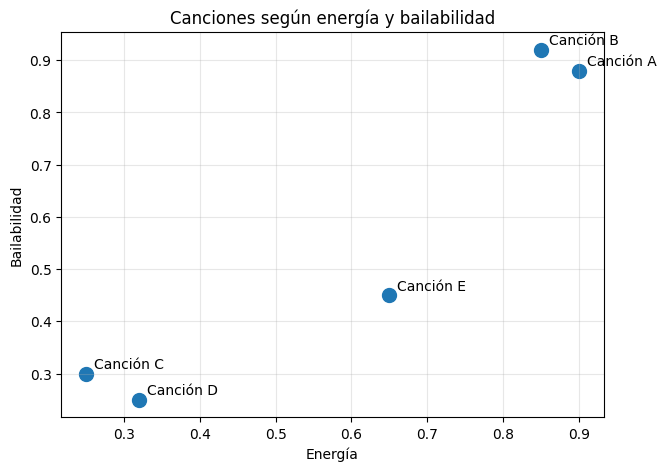

In [11]:
plt.figure(figsize=(7, 5))
plt.scatter(df["energia"], df["bailabilidad"], s=100)

for i, nombre in enumerate(df["cancion"]):
    plt.text(df["energia"][i] + 0.01, df["bailabilidad"][i] + 0.01, nombre)

plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("Canciones según energía y bailabilidad")
plt.grid(True, alpha=0.3)
plt.show()


### Preguntas para observar

1. ¿Ven grupos en el gráfico?
2. Si tuvieran que formar **tres grupos**, ¿dónde los ubicarían?
3. ¿Qué canciones pondrían juntas y por qué?


## 6. Introducción al clustering

**Clustering** significa agrupar elementos similares.

### Vocabulario

| Término | Significado |
|---|---|
| **Clustering** | El proceso de encontrar grupos |
| **Cluster** | Cada uno de los grupos encontrados |
| **Centroide** | El punto que representa el centro de un cluster |
| **K** | La cantidad de clusters que queremos obtener |

La idea:

> Queremos grupos cuyos elementos sean **parecidos entre sí** y **diferentes** de los de otros grupos.


## 7. ¿Qué significa K-Means?

El nombre del algoritmo resume su idea:

- **K** → cantidad de grupos.
- **Means** → medias/promedios usados para calcular los centroides.

Si queremos obtener tres grupos:


In [12]:
K = 3
print(f"Vamos a buscar {K} grupos de canciones.")


Vamos a buscar 3 grupos de canciones.


## 8. Funcionamiento conceptual del algoritmo

Antes de usar una librería, entendamos los pasos:

1. **Elegir K** (cantidad de grupos).
2. **Seleccionar centroides iniciales** (puntos de partida).
3. **Asignar** cada canción al centroide más cercano.
4. **Recalcular** los centroides como el promedio de las canciones de cada grupo.
5. **Repetir** hasta que los grupos se estabilicen.

### Analogía simple

Imaginen que eligen 3 puntos al azar en el gráfico. Cada canción "elige" el punto más cercano. Luego esos puntos se mueven al centro de sus canciones. Se vuelve a asignar... y así hasta que nadie cambie de grupo.


## 9. Distancia entre puntos

K-Means usa la **distancia euclídea** para decidir qué centroide está más cerca.

Para dos puntos $A=(x_1, y_1)$ y $B=(x_2, y_2)$:

$$d = \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}$$

### Idea importante

> K-Means utiliza la distancia para determinar qué centroide está más cerca de cada dato.

No hace falta memorizar la fórmula: lo importante es entender que **"más cerca" se mide con una distancia numérica**.


In [13]:
# Ejemplo: distancia entre Canción A y Canción C
import math

a = (0.90, 0.88)
c = (0.25, 0.30)

distancia = math.sqrt((c[0] - a[0]) ** 2 + (c[1] - a[1]) ** 2)
print(f"Distancia entre A y C: {distancia:.3f}")


Distancia entre A y C: 0.871


## 10. Implementación con Scikit-Learn

Ahora sí: usamos `sklearn` para aplicar K-Means.


In [14]:
X = df[["energia", "bailabilidad"]]
X


,energia,bailabilidad
0,0.90,0.88
1,0.85,0.92
2,0.25,0.30
3,0.32,0.25
4,0.65,0.45


El modelo recibe: la cantidad de grupos, el azar de los centroides iniciales y la cantidad de veces que se correrá el algoritmo.
- modelo.fit(X): parte de centroides, asigna cada canción al más cercano con la distancia euclídea, mueve los centroides al promedio de su grupo y repite hasta que los grupos dejan de cambiar.

In [15]:
modelo = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10,
)

modelo.fit(X)


,n_clusters,3
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


## 11. Obtener los grupos

El modelo asigna a cada canción un número de cluster.


In [16]:
df["cluster"] = modelo.labels_
df


,cancion,energia,bailabilidad,cluster
0,Canción A,0.90,0.88,0
1,Canción B,0.85,0.92,0
2,Canción C,0.25,0.30,1
3,Canción D,0.32,0.25,1
4,Canción E,0.65,0.45,2


### Importante

Los números `0`, `1` y `2` **no representan categorías reales**.

- El cluster `0` no es "mejor" que el `1`.
- Son solo identificadores.

> El algoritmo acaba de asignar cada canción a uno de los tres clusters.


## 12. Visualizar los resultados


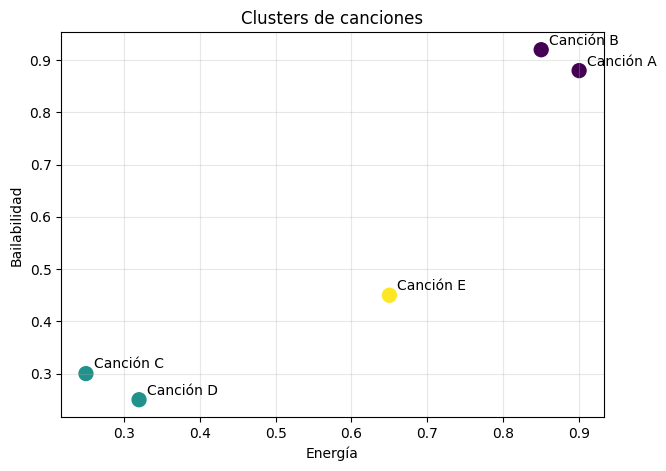

In [17]:
plt.figure(figsize=(7, 5))
plt.scatter(df["energia"], df["bailabilidad"], c=df["cluster"], s=100, cmap="viridis")

for i, nombre in enumerate(df["cancion"]):
    plt.text(df["energia"][i] + 0.01, df["bailabilidad"][i] + 0.01, nombre)

plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("Clusters de canciones")
plt.grid(True, alpha=0.3)
plt.show()


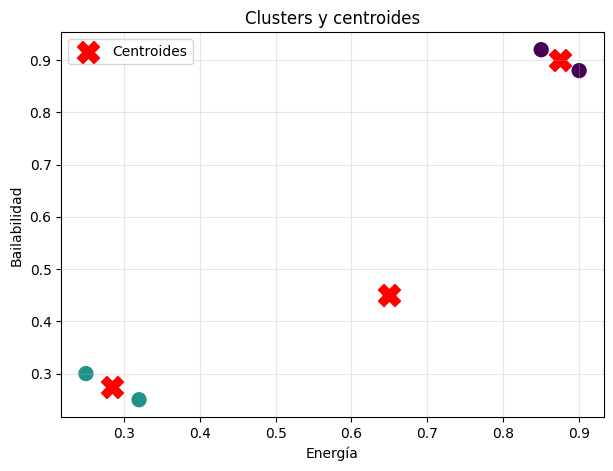

Centroides (energia, bailabilidad):
[[0.875 0.9  ]
 [0.285 0.275]
 [0.65  0.45 ]]


In [18]:
centroides = modelo.cluster_centers_

plt.figure(figsize=(7, 5))
plt.scatter(df["energia"], df["bailabilidad"], c=df["cluster"], s=100, cmap="viridis")
plt.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker="X",
    s=250,
    c="red",
    label="Centroides",
)

plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("Clusters y centroides")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Centroides (energia, bailabilidad):")
print(centroides)


## 13. Interpretación de los clusters

El algoritmo encuentra los grupos; **nosotros interpretamos qué significan**.


In [19]:
df.groupby("cluster")[["energia", "bailabilidad"]].mean()


,energia,bailabilidad
cluster,,
0,0.875,0.900
1,0.285,0.275
2,0.650,0.450


### Preguntas

1. ¿Qué características tiene cada grupo?
2. ¿Qué cluster contiene canciones más bailables?
3. ¿Qué cluster tiene mayor energía?
4. ¿Cómo podríamos describir cada grupo con palabras?

Ejemplo de interpretación posible:

- Un cluster de canciones **muy energéticas y bailables**.
- Un cluster de canciones **más tranquilas**.
- Un cluster **intermedio**.


## 14. ¿Qué pasa si elegimos otro K?

K-Means necesita que indiquemos K. Probemos con otros valores.


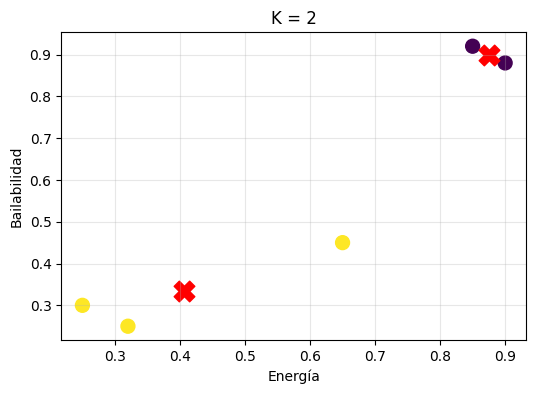

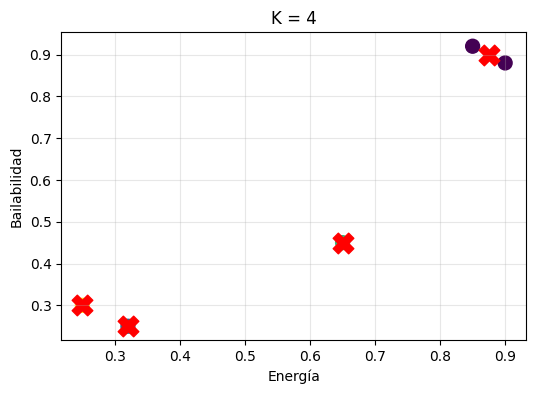

In [20]:
def entrenar_y_graficar(datos, k, titulo):
    X_local = datos[["energia", "bailabilidad"]]
    modelo_local = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo_local.fit_predict(X_local)

    plt.figure(figsize=(6, 4))
    plt.scatter(datos["energia"], datos["bailabilidad"], c=etiquetas, s=100, cmap="viridis")
    plt.scatter(
        modelo_local.cluster_centers_[:, 0],
        modelo_local.cluster_centers_[:, 1],
        marker="X",
        s=220,
        c="red",
    )
    plt.xlabel("Energía")
    plt.ylabel("Bailabilidad")
    plt.title(titulo)
    plt.grid(True, alpha=0.3)
    plt.show()

    return etiquetas

_ = entrenar_y_graficar(df, 2, "K = 2")
_ = entrenar_y_graficar(df, 4, "K = 4")


### Pregunta

> ¿Cuál parece ser el mejor número de clusters?

Esto introduce uno de los principales problemas de K-Means:

> **¿Cómo sabemos qué valor de K elegir?**


## 15. Método del codo

Una forma de orientarnos es mirar la **inercia**:

> La inercia mide qué tan "compactos" son los clusters (suma de distancias de cada punto a su centroide).

En general, al aumentar K la inercia baja. Buscamos un punto donde **agregar más clusters ya no mejora mucho** (el "codo" de la curva).


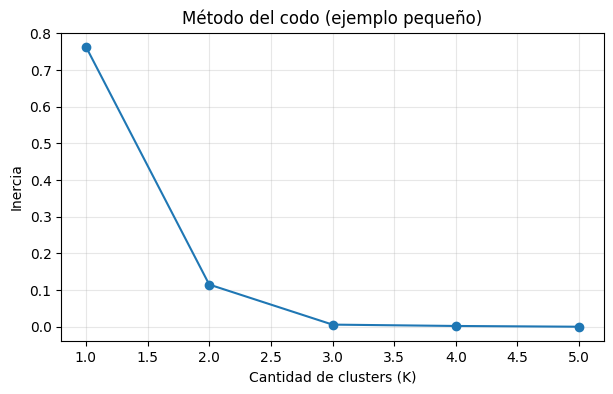

K=1: inercia=0.7635
K=2: inercia=0.1150
K=3: inercia=0.0058
K=4: inercia=0.0021
K=5: inercia=0.0000


In [21]:
X = df[["energia", "bailabilidad"]]

inercia = []
valores_k = range(1, 6)

for k in valores_k:
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_k.fit(X)
    inercia.append(modelo_k.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(valores_k, inercia, marker="o")
plt.xlabel("Cantidad de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo (ejemplo pequeño)")
plt.grid(True, alpha=0.3)
plt.show()

for k, valor in zip(valores_k, inercia):
    print(f"K={k}: inercia={valor:.4f}")


## 16. Actividad para los alumnos

Modifiquen el notebook y respondan:

### Actividad 1
Cambien `n_clusters=3` por `n_clusters=2` y analicen el resultado.

### Actividad 2
Prueben `n_clusters=4`.

### Actividad 3
Comparen y respondan:

1. ¿Qué ocurre cuando aumenta K?
2. ¿Qué pasa con el tamaño de los clusters?
3. ¿Qué valor de K elegirían?
4. ¿Por qué?


---

# Parte 2: dataset real de Spotify

Hasta ahora trabajamos con 5 canciones inventadas para entender la idea.

Ahora vamos a usar un **dataset público real** con 560 canciones de Spotify, con géneros contrastantes:

`acoustic`, `classical`, `jazz`, `ambient`, `dance`, `disco`, `edm`, `techno`, `rock`, `metal`, `hard-rock`, `hip-hop`, `reggae`, `latin`.

**Fuente:** [maharshipandya/spotify-tracks-dataset](https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset)

> Importante: la columna `genero` la usaremos solo para **interpretar** los resultados.
> K-Means **no** la verá durante el entrenamiento (aprendizaje no supervisado).


In [22]:
spotify = pd.read_csv("datos/canciones_spotify.csv")
spotify.head(10)


,cancion,artista,energia,bailabilidad,acustica,tempo,genero
0,18 ~eighteen~,Masaharu Fukuyama,0.760,0.609,0.131,117.1,acoustic
1,Too Much Heaven,Gail Blanco,0.450,0.664,0.781,84.0,acoustic
2,Fate of a Coward,Days N Daze,0.534,0.583,0.569,123.1,acoustic
3,彼方で,Masaharu Fukuyama,0.570,0.459,0.199,73.0,acoustic
4,Somebody Loved,Kina Grannis,0.107,0.612,0.936,78.4,acoustic
5,世界中の誰よりきっと,Mone Kamishiraishi,0.636,0.578,0.087,124.9,acoustic
6,"He's A Pirate (From ""Pirates of the Caribbean"")",Beyond The Guitar,0.454,0.570,0.881,101.5,acoustic
7,More Than Gravity,Colin & Caroline,0.468,0.620,0.715,111.0,acoustic
8,Still Falling For You - Acoustic,Sara Farell;Simon Samaeng,0.298,0.375,0.822,174.0,acoustic
9,Please Don't Say You Love Me,Gabrielle Aplin,0.541,0.479,0.737,86.0,acoustic


In [23]:
print("Cantidad de canciones:", len(spotify))
print("\nCanciones por género:")
print(spotify["genero"].value_counts())
spotify.describe()


Cantidad de canciones: 560

Canciones por género:
genero
acoustic     40
ambient      40
classical    40
dance        40
disco        40
edm          40
hard-rock    40
hip-hop      40
jazz         40
latin        40
metal        40
reggae       40
rock         40
techno       40
Name: count, dtype: int64


,energia,bailabilidad,acustica,tempo
count,560.000000,560.000000,560.000000,560.000000
mean,0.612752,0.586737,0.306371,119.311786
std,0.251345,0.181143,0.339971,29.521707
min,0.002000,0.092000,0.000000,47.800000
25%,0.482000,0.464000,0.020750,96.100000
50%,0.666000,0.605500,0.133500,120.000000
75%,0.808000,0.718250,0.581250,136.000000
max,0.992000,0.937000,0.995000,214.000000


## 17. Extensión: más características y datos reales

Primero repetimos el análisis en 2D (`energia` vs `bailabilidad`) con el dataset real.


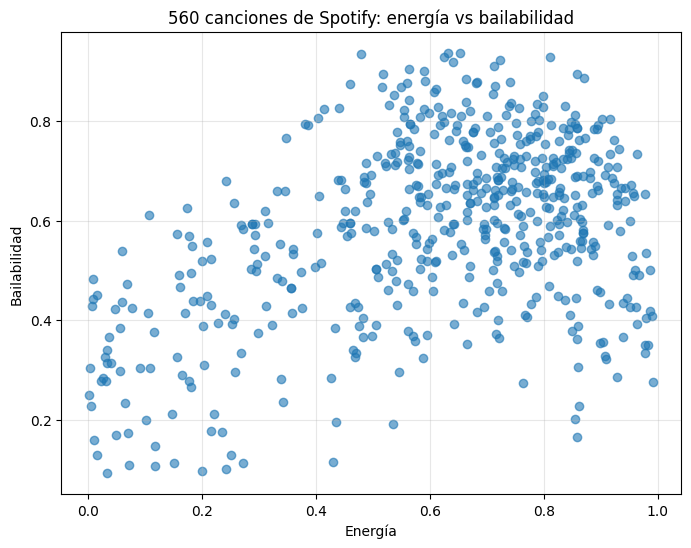

In [24]:
plt.figure(figsize=(8, 6))
plt.scatter(spotify["energia"], spotify["bailabilidad"], alpha=0.6)
plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("560 canciones de Spotify: energía vs bailabilidad")
plt.grid(True, alpha=0.3)
plt.show()


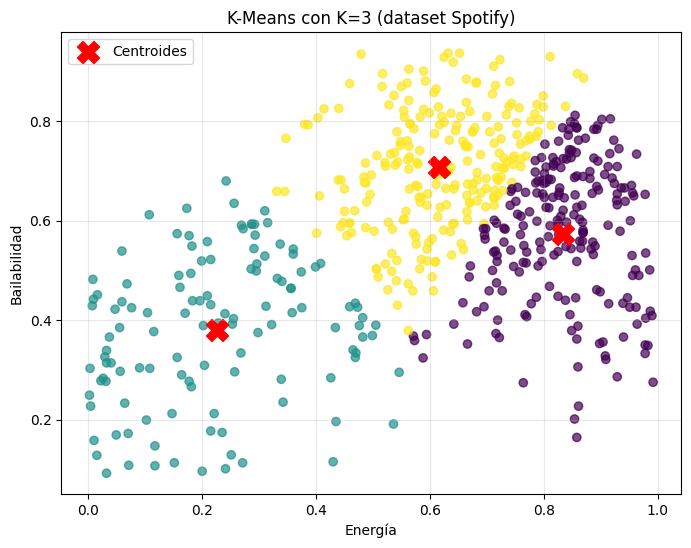

,energia,bailabilidad
cluster_2d,,
0,0.833443,0.574243
1,0.225533,0.380639
2,0.616680,0.708526


In [25]:
X_spotify_2d = spotify[["energia", "bailabilidad"]]

modelo_spotify = KMeans(n_clusters=3, random_state=42, n_init=10)
spotify["cluster_2d"] = modelo_spotify.fit_predict(X_spotify_2d)

plt.figure(figsize=(8, 6))
plt.scatter(
    spotify["energia"],
    spotify["bailabilidad"],
    c=spotify["cluster_2d"],
    cmap="viridis",
    alpha=0.7,
)
plt.scatter(
    modelo_spotify.cluster_centers_[:, 0],
    modelo_spotify.cluster_centers_[:, 1],
    marker="X",
    s=250,
    c="red",
    label="Centroides",
)
plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("K-Means con K=3 (dataset Spotify)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

spotify.groupby("cluster_2d")[["energia", "bailabilidad"]].mean()


### Interpretación con géneros (solo para validar)

Aunque K-Means no usó el género, podemos ver qué géneros predominan en cada cluster.


In [26]:
pd.crosstab(spotify["cluster_2d"], spotify["genero"])


genero,acoustic,ambient,classical,dance,disco,edm,hard-rock,hip-hop,jazz,latin,metal,reggae,rock,techno
cluster_2d,,,,,,,,,,,,,,
0,10,2,1,15,20,21,26,12,2,18,36,10,19,18
1,12,35,38,0,3,0,3,0,24,0,1,0,5,1
2,18,3,1,25,17,19,11,28,14,22,3,30,16,21


0 = muy intensa, bailable a medias. 1 = tranquila. 2 = Bailable

Ahora ampliamos a **4 características**:

- `energia`
- `bailabilidad`
- `acustica`
- `tempo`

> Antes usábamos dos características porque podíamos graficarlas fácilmente.
> K-Means no está limitado a dos dimensiones.


In [27]:
features = ["energia", "bailabilidad", "acustica", "tempo"]
X_multi = spotify[features]
X_multi.head()


,energia,bailabilidad,acustica,tempo
0,0.760,0.609,0.131,117.1
1,0.450,0.664,0.781,84.0
2,0.534,0.583,0.569,123.1
3,0.570,0.459,0.199,73.0
4,0.107,0.612,0.936,78.4


## 18. Normalización de datos

Acá aparece un problema importante:

- `energia`, `bailabilidad` y `acustica` están aproximadamente entre 0 y 1.
- `tempo` está entre ~50 y ~200.

Como K-Means usa distancias, **el tempo dominaría** el cálculo si no normalizamos.

Usamos `StandardScaler` para poner todas las variables en una escala comparable.


In [29]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_multi)

# Vista rápida de las primeras filas ya normalizadas
pd.DataFrame(X_scaled, columns=features).head()


,energia,bailabilidad,acustica,tempo
0,0.586364,0.123010,-0.516304,-0.074988
1,-0.648102,0.426909,1.397335,-1.197199
2,-0.313601,-0.020651,0.773194,0.128434
3,-0.170244,-0.705805,-0.316108,-1.570139
4,-2.013979,0.139586,1.853664,-1.387059


### Cómo se ve el problema de las escalas

En el gráfico de la izquierda, `tempo` ocupa casi todo el eje y las otras tres variables quedan aplastadas cerca de cero. K-Means mediría casi solo el tempo.

A la derecha, después de `StandardScaler`, las cuatro cajas tienen un tamaño parecido: media cercana a 0 y desvío cercano a 1.


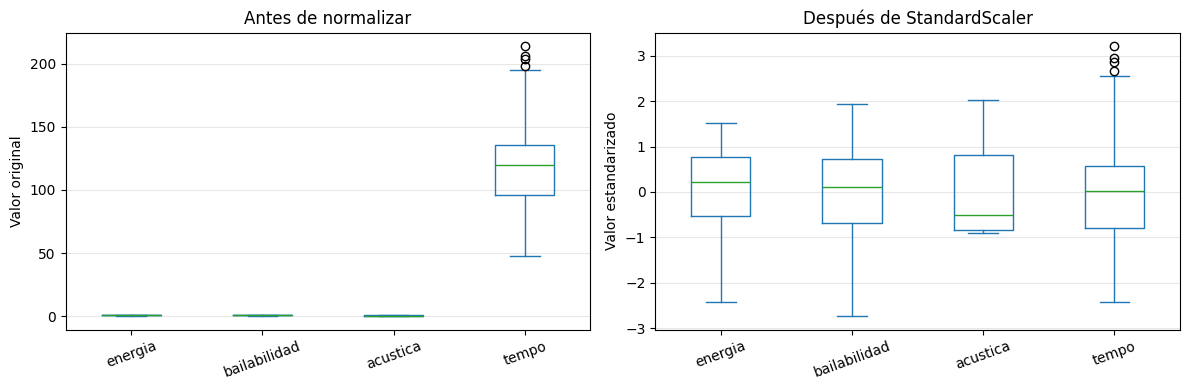

In [30]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

spotify[features].plot(kind="box", ax=ejes[0])
ejes[0].set_title("Antes de normalizar")
ejes[0].set_ylabel("Valor original")
ejes[0].tick_params(axis="x", rotation=20)
ejes[0].grid(True, axis="y", alpha=0.3)

pd.DataFrame(X_scaled, columns=features).plot(kind="box", ax=ejes[1])
ejes[1].set_title("Después de StandardScaler")
ejes[1].set_ylabel("Valor estandarizado")
ejes[1].tick_params(axis="x", rotation=20)
ejes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


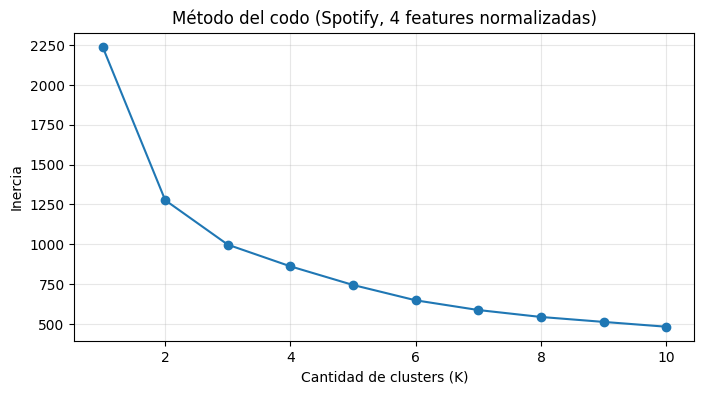

In [31]:
# Método del codo con datos normalizados
inercia_real = []
valores_k_real = range(1, 11)

for k in valores_k_real:
    modelo_k = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo_k.fit(X_scaled)
    inercia_real.append(modelo_k.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(valores_k_real, inercia_real, marker="o")
plt.xlabel("Cantidad de clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del codo (Spotify, 4 features normalizadas)")
plt.grid(True, alpha=0.3)
plt.show()


In [32]:
# Elegimos K=4 como valor razonable para interpretar
K_final = 4

modelo_final = KMeans(n_clusters=K_final, random_state=42, n_init=10)
spotify["cluster"] = modelo_final.fit_predict(X_scaled)

# Perfil promedio de cada cluster (en escala original)
perfiles = spotify.groupby("cluster")[features].mean().round(3)
perfiles


,energia,bailabilidad,acustica,tempo
cluster,,,,
0,0.698,0.714,0.170,107.277
1,0.271,0.413,0.825,86.893
2,0.787,0.540,0.074,145.001
3,0.283,0.408,0.755,147.336


La tabla de promedios mezcla escalas distintas (`tempo` está cerca de 100 y el resto entre 0 y 1), así que cuesta comparar.

En el gráfico de la derecha cada barra está en la **escala normalizada**: 0 es el promedio de todas las canciones. Una barra positiva significa "más alto que el promedio"; una negativa, "más bajo".


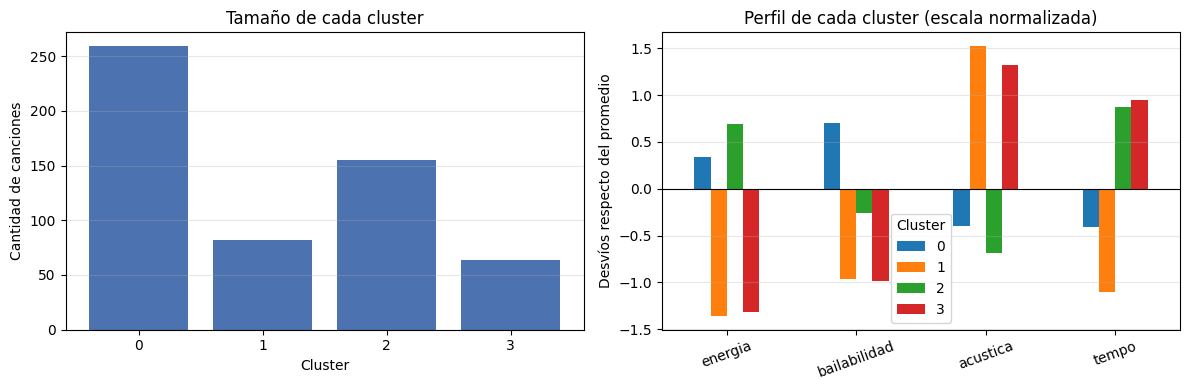

In [33]:
centroides_norm = pd.DataFrame(modelo_final.cluster_centers_, columns=features)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

conteo = spotify["cluster"].value_counts().sort_index()
ejes[0].bar(conteo.index.astype(str), conteo.values, color="#4C72B0")
ejes[0].set_xlabel("Cluster")
ejes[0].set_ylabel("Cantidad de canciones")
ejes[0].set_title("Tamaño de cada cluster")
ejes[0].grid(True, axis="y", alpha=0.3)

centroides_norm.T.plot(kind="bar", ax=ejes[1])
ejes[1].axhline(0, color="black", linewidth=0.8)
ejes[1].set_title("Perfil de cada cluster (escala normalizada)")
ejes[1].set_ylabel("Desvíos respecto del promedio")
ejes[1].tick_params(axis="x", rotation=20)
ejes[1].grid(True, axis="y", alpha=0.3)
ejes[1].legend(title="Cluster")

plt.tight_layout()
plt.show()


In [52]:
# ¿Qué géneros aparecen más en cada cluster?
for k in range(K_final):
    print(f"\n=== Cluster {k} ===")
    print(perfiles.loc[k])
    print("Géneros más frecuentes:")
    print(spotify.loc[spotify["cluster"] == k, "genero"].value_counts().head(5))



=== Cluster 0 ===
energia           0.698
bailabilidad      0.714
acustica          0.170
tempo           107.277
Name: 0, dtype: float64
Géneros más frecuentes:
genero
dance      32
reggae     30
techno     28
edm        27
hip-hop    27
Name: count, dtype: int64

=== Cluster 1 ===
energia          0.271
bailabilidad     0.413
acustica         0.825
tempo           86.893
Name: 1, dtype: float64
Géneros más frecuentes:
genero
classical    25
ambient      24
jazz         14
acoustic     11
hip-hop       4
Name: count, dtype: int64

=== Cluster 2 ===
energia           0.787
bailabilidad      0.540
acustica          0.074
tempo           145.001
Name: 2, dtype: float64
Géneros más frecuentes:
genero
metal        29
hard-rock    26
rock         16
latin        15
edm          13
Name: count, dtype: int64

=== Cluster 3 ===
energia           0.283
bailabilidad      0.408
acustica          0.755
tempo           147.336
Name: 3, dtype: float64
Géneros más frecuentes:
genero
ambient      15


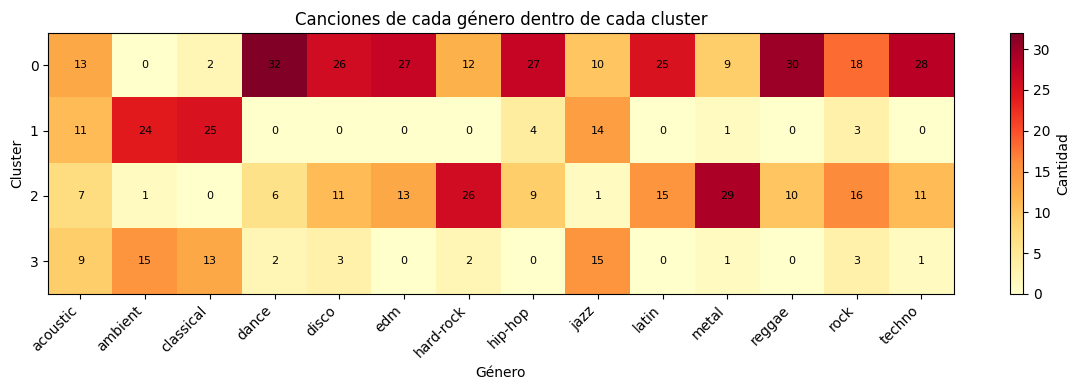

In [34]:
# Mapa de calor: cuántas canciones de cada género caen en cada cluster
tabla_generos = pd.crosstab(spotify["cluster"], spotify["genero"])

fig, ax = plt.subplots(figsize=(12, 4))
imagen = ax.imshow(tabla_generos.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(tabla_generos.columns)))
ax.set_xticklabels(tabla_generos.columns, rotation=45, ha="right")
ax.set_yticks(range(len(tabla_generos.index)))
ax.set_yticklabels(tabla_generos.index)
ax.set_xlabel("Género")
ax.set_ylabel("Cluster")
ax.set_title("Canciones de cada género dentro de cada cluster")

for fila in range(tabla_generos.shape[0]):
    for columna in range(tabla_generos.shape[1]):
        ax.text(
            columna,
            fila,
            int(tabla_generos.values[fila, columna]),
            ha="center",
            va="center",
            fontsize=8,
        )

fig.colorbar(imagen, ax=ax, label="Cantidad")
plt.tight_layout()
plt.show()


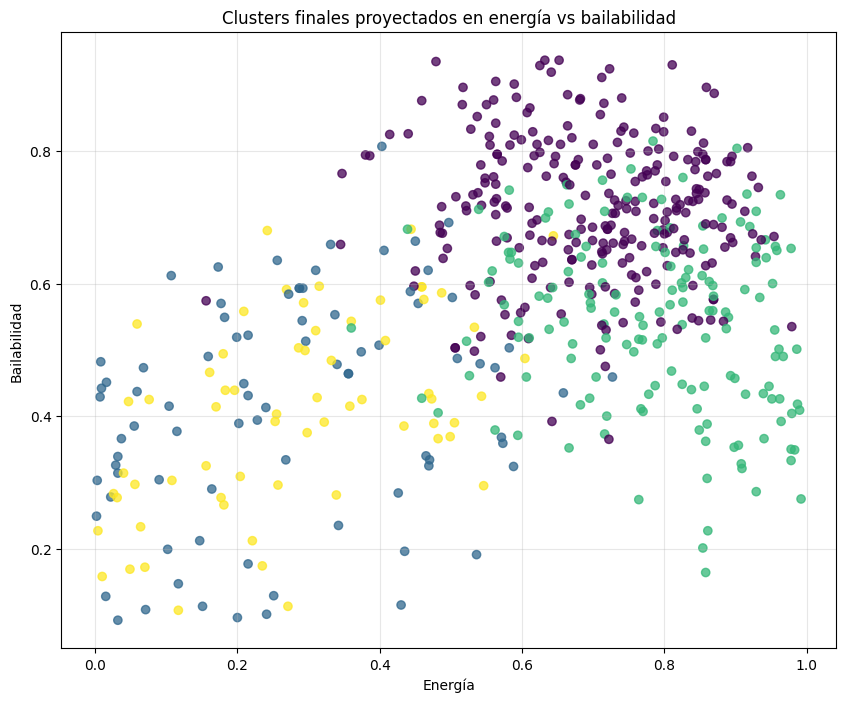

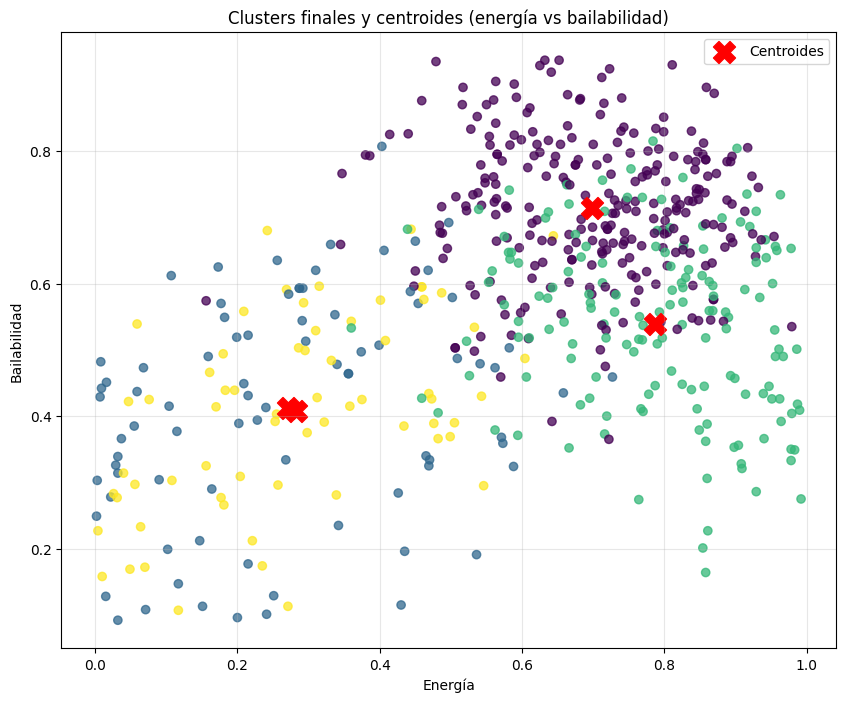

In [43]:
# Visualización 2D de los clusters obtenidos en 4D
# (solo para ver el resultado; el modelo usó 4 features)
plt.figure(figsize=(10, 8))
plt.scatter(
    spotify["energia"],
    spotify["bailabilidad"],
    c=spotify["cluster"],
    cmap="viridis",
    alpha=0.75,
)
plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("Clusters finales proyectados en energía vs bailabilidad")
plt.grid(True, alpha=0.3)
plt.show()

# Mismos puntos, con los centroides del modelo 4D
# (se deshace el StandardScaler para dibujarlos en la escala original)
centroides_orig = scaler.inverse_transform(modelo_final.cluster_centers_)

plt.figure(figsize=(10, 8))
plt.scatter(
    spotify["energia"],
    spotify["bailabilidad"],
    c=spotify["cluster"],
    cmap="viridis",
    alpha=0.75,
)
plt.scatter(
    centroides_orig[:, 0],
    centroides_orig[:, 1],
    marker="X",
    s=250,
    c="red",
    label="Centroides",
)
plt.xlabel("Energía")
plt.ylabel("Bailabilidad")
plt.title("Clusters finales y centroides (energía vs bailabilidad)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


El gráfico anterior usa solo energía y bailabilidad, así que dos clusters parecidos en esas dos variables pueden quedar superpuestos.

Estas otras vistas usan **acústica** y **tempo**, que son justo las características que los separan. Los diagramas de caja muestran la distribución completa, no solo el promedio.


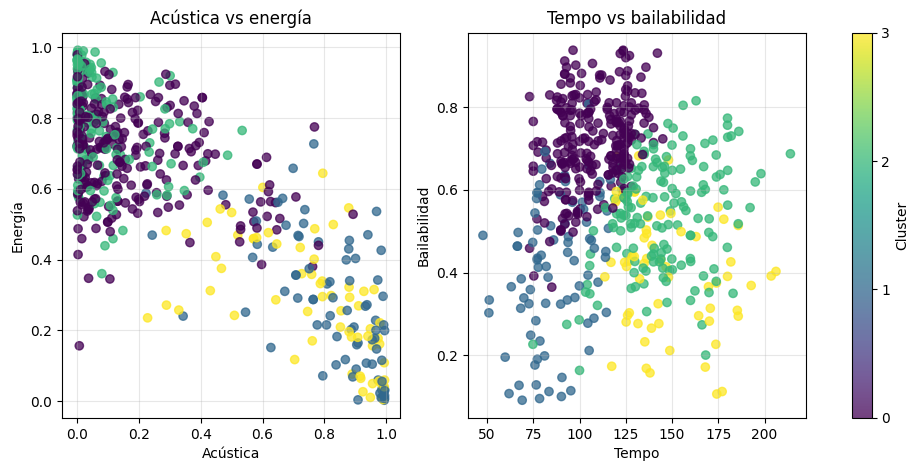

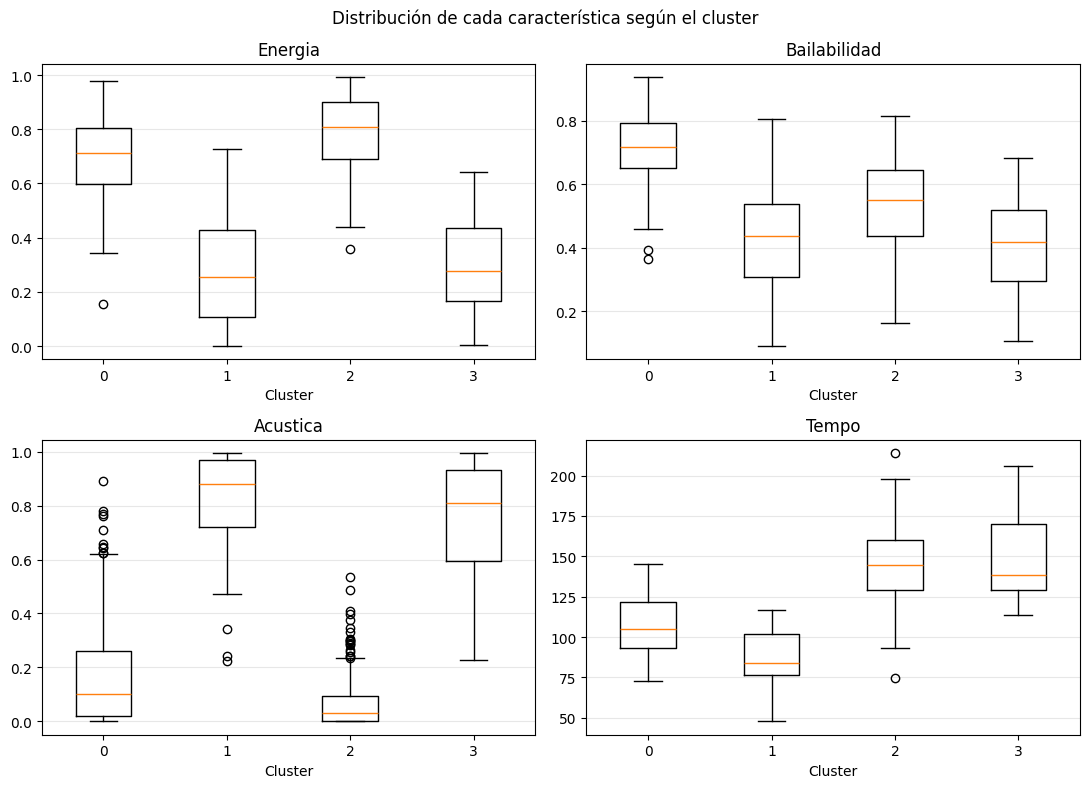

In [37]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))

ejes[0].scatter(
    spotify["acustica"],
    spotify["energia"],
    c=spotify["cluster"],
    cmap="viridis",
    alpha=0.75,
)
ejes[0].set_xlabel("Acústica")
ejes[0].set_ylabel("Energía")
ejes[0].set_title("Acústica vs energía")
ejes[0].grid(True, alpha=0.3)

scatter = ejes[1].scatter(
    spotify["tempo"],
    spotify["bailabilidad"],
    c=spotify["cluster"],
    cmap="viridis",
    alpha=0.75,
)
ejes[1].set_xlabel("Tempo")
ejes[1].set_ylabel("Bailabilidad")
ejes[1].set_title("Tempo vs bailabilidad")
ejes[1].grid(True, alpha=0.3)

fig.colorbar(scatter, ax=ejes, label="Cluster", ticks=range(K_final))
plt.show()

fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
for ax, columna in zip(ejes.ravel(), features):
    datos_box = [
        spotify.loc[spotify["cluster"] == k, columna] for k in range(K_final)
    ]
    ax.boxplot(datos_box)
    ax.set_xticklabels([str(k) for k in range(K_final)])
    ax.set_title(columna.capitalize())
    ax.set_xlabel("Cluster")
    ax.grid(True, axis="y", alpha=0.3)

plt.suptitle("Distribución de cada característica según el cluster")
plt.tight_layout()
plt.show()


In [38]:
# Algunas canciones de ejemplo por cluster
for k in range(K_final):
    ejemplo = spotify.loc[
        spotify["cluster"] == k, ["cancion", "artista", "genero"]
    ].head(5)
    print(f"\nEjemplos del cluster {k}:")
    print(ejemplo.to_string(index=False))



Ejemplos del cluster 0:
         cancion           artista   genero
   18 ~eighteen~ Masaharu Fukuyama acoustic
Fate of a Coward       Days N Daze acoustic
             彼方で Masaharu Fukuyama acoustic
          Pilots       Andrew Ripp acoustic
    Kaleidoscope A Great Big World acoustic

Ejemplos del cluster 1:
                                        cancion           artista   genero
                                Too Much Heaven       Gail Blanco acoustic
                                 Somebody Loved      Kina Grannis acoustic
He's A Pirate (From "Pirates of the Caribbean") Beyond The Guitar acoustic
                              More Than Gravity  Colin & Caroline acoustic
                   Please Don't Say You Love Me   Gabrielle Aplin acoustic

Ejemplos del cluster 2:
       cancion            artista   genero
    世界中の誰よりきっと Mone Kamishiraishi acoustic
          音タイム        Hanare Gumi acoustic
    Northbound       Grace Petrie acoustic
 Nickel Plated           Get Dead acous

### Cómo interpretar (guía)

Usen juntos la tabla de promedios, el gráfico de perfiles en escala normalizada, los diagramas de caja y el mapa de géneros.

Mirando esos resultados, pueden proponer etiquetas humanas, por ejemplo:

- Canciones **acústicas / tranquilas** (alta `acustica`, baja `energia`).
- Canciones **bailables / electrónicas** (alta `bailabilidad` y `energia`).
- Canciones **rock/metal intensas** (alta `energia`, menor `bailabilidad`).
- Canciones **intermedias**.

Recuerden: esas etiquetas las inventamos nosotros; el algoritmo solo devolvió números.


## 19. ¿Qué aprendimos?

```text
Datos
  ↓
Características
  ↓
Distancias
  ↓
K-Means
  ↓
Clusters
  ↓
Centroides
  ↓
Interpretación
```

### Conceptos

- Machine Learning
- Aprendizaje no supervisado
- Clustering / Cluster
- K
- Centroide
- Distancia
- K-Means
- Inercia
- Método del codo
- Normalización


## 20. Preguntas de cierre

1. ¿Por qué K-Means es un algoritmo de aprendizaje no supervisado?
2. ¿Qué representa K?
3. ¿Qué es un centroide?
4. ¿Cómo decide K-Means a qué cluster pertenece un dato?
5. ¿Qué ocurre cuando modificamos K?
6. ¿Por qué los clusters `0`, `1` y `2` no tienen un significado específico?
7. ¿Para qué sirve el método del codo?
8. ¿Por qué puede ser necesario normalizar los datos?
9. ¿Qué pasaría si agregáramos muchas características?
10. ¿Qué diferencia habría entre decirle al algoritmo el género de cada canción y dejar que encuentre los grupos por sí mismo?


## Créditos del dataset

- **Dataset:** Spotify Tracks Dataset
- **Autor:** Maharshi Pandya
- **Fuente:** https://huggingface.co/datasets/maharshipandya/spotify-tracks-dataset
- **Contenido usado en clase:** subconjunto de 560 canciones (`datos/canciones_spotify.csv`) con las columnas `cancion`, `artista`, `energia`, `bailabilidad`, `acustica`, `tempo`, `genero`.
